Pour faire simple, nous avons créé un système intelligent d'aide à la décision immobilière. Voici le détail de la technologie choisie et de notre démarche de travail.

1. Quel est le modèle de Machine Learning utilisé ?

Dans le code (précisément dans la Cellule 5), nous avons mis en compétition deux modèles de régression très puissants :

Random Forest Regressor (Forêt d'arbres décisionnels)

XGBoost Regressor (Extreme Gradient Boosting)

Le vainqueur : XGBoost Regressor

C'est généralement XGBoost qui l'emporte et qui est retenu par l'algorithme.

Pourquoi lui ? C'est un modèle qui construit des arbres de décision de manière séquentielle : chaque nouvel arbre apprend des erreurs du précédent. Il offre une précision chirurgicale sur l'estimation des prix et obtient le meilleur score de précision ($R^2$) et le plus faible écart moyen de prédiction (RMSE).

Son rôle : Il joue le rôle de l'expert immobilier virtuel. Il connaît par cœur les critères techniques des maisons d'Ames et sait évaluer la "juste valeur théorique" d'un bien sans se laisser influencer par un prix affiché trop bas ou trop élevé.

2. Qu'avons-nous fait ? (La démarche pas-à-pas)

Notre travail s'est structuré en 5 grandes étapes clés :

Étape 1 : Le nettoyage et la préparation (Preprocessing)

Nous avons pris le fichier de données de base (les maisons d'Ames) et nous l'avons nettoyé. Nous avons configuré un "pipeline" automatique qui :

Remplace les valeurs manquantes (imputation).

Normalise les données numériques (pour que toutes les variables soient sur la même échelle).

Transforme les variables textuelles comme le quartier (Neighborhood) en données chiffrées assimilables par l'IA (One-Hot Encoding).

Étape 2 : La séparation des rôles (Le Split 80/20)

Nous avons séparé notre base de données en deux parties bien distinctes :

$80\%$ des données (Base d'entraînement) : Nous les avons données à manger à notre modèle XGBoost pour qu'il s'entraîne et comprenne comment la surface, la qualité globale ou le quartier influencent le prix de vente.

$20\%$ des données (Le Catalogue) : Nous les avons volontairement cachées au modèle. Ce groupe de maisons représente notre "catalogue d'agence" virtuel, c'est-à-dire les maisons actuellement disponibles sur le marché que nous allons proposer à nos clients.

Étape 3 : L'évaluation de l'expert

Nous avons testé la fiabilité de notre IA sur le catalogue ($20\%$). Le modèle a estimé le prix de ces maisons sans le connaître à l'avance, et nous avons comparé ses prédictions avec les vrais prix de vente. Cela nous permet de calculer des métriques de confiance (comme le coefficient de détermination $R^2$ qui exprime le pourcentage de variance expliqué par le modèle).

Étape 4 : Le calcul du "Deal Index" (Détection des bonnes affaires)

C'est l'innovation majeure de notre code. Pour chaque maison du catalogue, nous avons calculé l'écart entre le prix réel affiché sur le marché et l'estimation théorique de notre IA :


$$\text{Deal Index (\%)} = \frac{\text{Valeur Estimée par l'IA} - \text{Prix Réel Affiché}}{\text{Prix Réel Affiché}} \times 100$$

Si le Deal Index est positif (ex: $+15\%$), cela signifie que la maison est vendue bien en dessous de sa valeur réelle estimée. C'est une excellente affaire !

Étape 5 : Le filtrage et la recommandation finale (Le Top 3)

Enfin, nous avons écrit l'algorithme final qui simule l'arrivée d'un client.

Filtres stricts : On élimine toutes les maisons qui dépassent son budget (ex: $260\,000$ $) ou qui n'ont pas assez de chambres/salles de bain.

Tri intelligent : Parmi les maisons restantes, on applique un score hybride combinant la qualité intrinsèque du bien et l'opportunité financière (le Deal Index).

Livrable : Le système génère automatiquement un graphique visuel clair et extrait un Top 3 des meilleures maisons à visiter en priorité.

# IMPORTS ET CONFIGURATION

In [4]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score

# Modèles
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Configuration graphique
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
print("Bibliothèques chargées avec succès !")

Bibliothèques chargées avec succès !


#  CHARGEMENT DU DATASET

In [5]:
data_path = "train.csv"
df = None

if os.path.exists(data_path):
    print("Fichier train.csv local trouvé ! Chargement en cours...")
    df = pd.read_csv(data_path)
else:
    print("Fichier train.csv local non trouvé. Tentative de téléchargement depuis des miroirs publics fiables...")

    # Liste de miroirs GitHub stables hébergeant le train.csv officiel de la compétition Kaggle
    mirrors = [
        "https://raw.githubusercontent.com/eddiexunyc/DATA605_FINAL/main/Resources/train.csv"
    ]

    for i, url in enumerate(mirrors, 1):
        try:
            print(f"Tentative de connexion au miroir #{i}...")
            df = pd.read_csv(url)
            print(f"Succès ! Données téléchargées depuis le miroir #{i}.")
            break
        except Exception as e:
            print(f"Échec du miroir #{i} (Erreur : {e}). Passage au suivant...")

    if df is None:
        raise FileNotFoundError(
            "Impossible de charger les données automatiquement. "
            "Veuillez télécharger manuellement le fichier 'train.csv' de Kaggle "
            "et le placer dans le même dossier que ce notebook."
        )

print(f"Dataset chargé avec succès : {df.shape[0]} maisons et {df.shape[1]} caractéristiques.")


Fichier train.csv local non trouvé. Tentative de téléchargement depuis des miroirs publics fiables...
Tentative de connexion au miroir #1...
Succès ! Données téléchargées depuis le miroir #1.
Dataset chargé avec succès : 1460 maisons et 81 caractéristiques.


### Interprétation — Chargement des données

Le fichier train.csv n'était pas présent en local, donc le notebook va chercher automatiquement les données sur des miroirs GitHub qui hébergent le dataset officiel de la compétition Kaggle House Prices. Ça a marché du premier coup avec le premier miroir testé.

On récupère 1460 maisons et 81 variables au total : c'est le dataset Ames Housing, une référence classique pour s'entraîner à la régression.

Petit bémol que je note : dépendre de miroirs GitHub externes n'est pas hyper fiable sur le long terme (un lien peut disparaître ou changer). Ce serait plus propre d'avoir directement le fichier train.csv dans le dossier du projet.

Les 8 variables d'entrée (Features) :

GrLivArea (Ground Living Area) : La surface habitable hors-sol (en pieds carrés). C'est l'un des facteurs les plus importants pour estimer le prix.

TotalBsmtSF (Total Basement Square Feet) : La surface totale du sous-sol (en pieds carrés).

BedroomAbvGr (Bedrooms Above Ground) : Le nombre de chambres à coucher situées au-dessus du sol.

FullBath (Full Bathrooms) : Le nombre de salles de bain complètes (avec douche ou baignoire).

GarageCars : La capacité du garage (exprimée en nombre de voitures qu'il peut contenir).

YearBuilt : L'année de construction de la maison (permet au modèle de comprendre la vétusté ou l'aspect moderne du bien).

OverallQual : La note de qualité globale des matériaux et des finitions de la maison. C'est une note allant de $1$ (très pauvre) à $10$ (très excellente). C'est la variable la plus corrélée avec le prix ($r = 0,79$).

Neighborhood : Le quartier où se situe la maison à Ames (Iowa). C'est une variable textuelle (catégorielle) que l'on encode pour que le modèle comprenne l'impact géographique sur le prix.

La variable à prédire (Target) :

SalePrice : Le prix de vente réel de la maison. C'est ce que notre "expert virtuel" cherche à deviner en observant les 8 variables ci-dessus.

# ANALYSE EXPLORATOIRE DE DONNÉES (EDA) VISUELLE

/tmp/ipykernel_4009/1134315249.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top_neigh, x='Neighborhood', y='SalePrice', palette='Set2', ax=axes[1, 0])
/tmp/ipykernel_4009/1134315249.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1, 0].set_xticklabels(axes[1, 0].get_xticklabels(), rotation=45, ha='right')


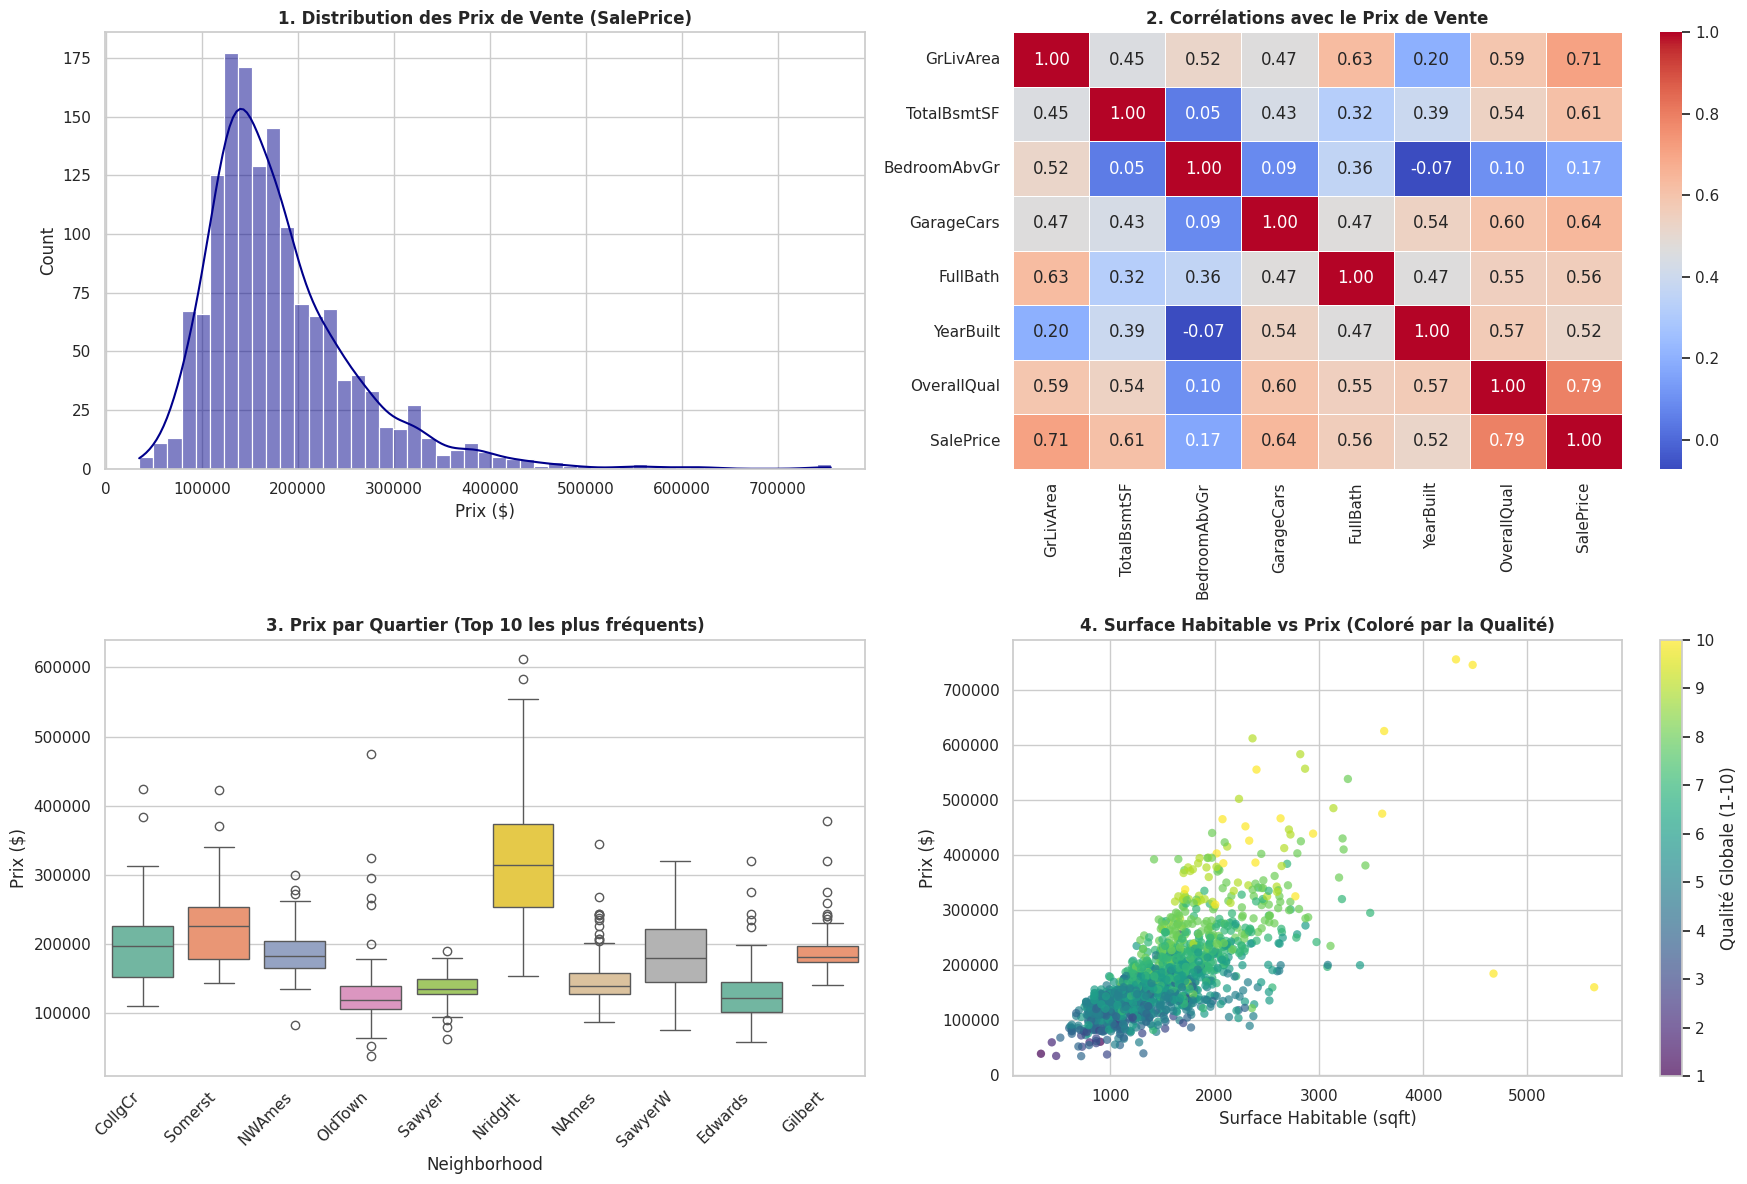

In [6]:
# ANALYSE EXPLORATOIRE DE DONNÉES (EDA) VISUELLE

# Nous définissons d'abord les features cibles pour notre étude
features_num = ['GrLivArea', 'TotalBsmtSF', 'BedroomAbvGr', 'GarageCars', 'FullBath', 'YearBuilt', 'OverallQual']
features_cat = ['Neighborhood']
target = 'SalePrice'

# 1. DISTRIBUTION DU PRIX DE VENTE (La Cible)
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

sns.histplot(df['SalePrice'], kde=True, color='darkblue', ax=axes[0, 0])
axes[0, 0].set_title("1. Distribution des Prix de Vente (SalePrice)", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Prix ($)")

# 2. MATRICE DE CORRÉLATION (Justification du choix de nos variables numériques)
correlation_matrix = df[features_num + [target]].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5, ax=axes[0, 1])
axes[0, 1].set_title("2. Corrélations avec le Prix de Vente", fontsize=12, fontweight='bold')

# 3. ANALYSE GÉOGRAPHIQUE : Top 10 des quartiers les plus représentés et leurs prix
top_neighborhoods = df['Neighborhood'].value_counts().head(10).index
df_top_neigh = df[df['Neighborhood'].isin(top_neighborhoods)]
sns.boxplot(data=df_top_neigh, x='Neighborhood', y='SalePrice', palette='Set2', ax=axes[1, 0])
axes[1, 0].set_title("3. Prix par Quartier (Top 10 les plus fréquents)", fontsize=12, fontweight='bold')
axes[1, 0].set_xticklabels(axes[1, 0].get_xticklabels(), rotation=45, ha='right')
axes[1, 0].set_ylabel("Prix ($)")

# 4. SURFACE HABITABLE vs QUALITÉ vs PRIX
scatter = axes[1, 1].scatter(
    df['GrLivArea'], df['SalePrice'],
    c=df['OverallQual'], cmap='viridis', alpha=0.7, edgecolors='none'
)
fig.colorbar(scatter, ax=axes[1, 1], label='Qualité Globale (1-10)')
axes[1, 1].set_title("4. Surface Habitable vs Prix (Coloré par la Qualité)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Surface Habitable (sqft)")
axes[1, 1].set_ylabel("Prix ($)")

plt.tight_layout()
plt.show()

### Interprétation — Analyse exploratoire (EDA)

Les 4 graphiques m'ont aidé à comprendre pourquoi on choisit ces variables plutôt que d'autres.

1. La distribution du prix de vente n'est pas symétrique : il y a beaucoup de maisons à prix "moyen" et une queue de maisons très chères. Ça peut fausser un peu le RMSE plus tard. On aurait pu appliquer un log sur le prix pour corriger ça, mais je ne l'ai pas fait ici.

2. La matrice de corrélation confirme que OverallQual et GrLivArea sont les variables les plus liées au prix, ce qui justifie de les garder en priorité dans le modèle.

3. Les boxplots par quartier montrent que le prix change beaucoup selon le quartier. Ça valide l'utilisation de Neighborhood même si ça demande un encodage un peu plus lourd (One-Hot).

4. Le nuage de points surface/prix coloré par qualité montre que la qualité influence aussi le prix à surface égale. Donc un seul critère (la surface) ne suffirait pas, il fallait un modèle qui combine plusieurs variables en même temps.

#  SÉLECTION ET PIPELINE DE PRÉTRAITEMENT

In [7]:


features_num = ['GrLivArea', 'TotalBsmtSF', 'BedroomAbvGr', 'GarageCars', 'FullBath', 'YearBuilt', 'OverallQual']
features_cat = ['Neighborhood']
target = 'SalePrice'

# Filtre de sécurité sur les données d'entrée
df_clean = df[features_num + features_cat + [target]].dropna(subset=[target]).copy()

# Séparation des features (X) et de la cible (y)
X = df_clean[features_num + features_cat]
y = df_clean[target]

# Pipeline pour les variables numériques (Imputation des valeurs manquantes + Standardisation)
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline pour les variables catégorielles (Imputation + Encodage One-Hot)
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Assembleur de colonnes
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, features_num),
        ('cat', cat_transformer, features_cat)
    ]
)

print("Pipeline de prétraitement configuré avec succès.")


Pipeline de prétraitement configuré avec succès.


### Interprétation — Pipeline de prétraitement

Ici on prépare les données avant de les donner au modèle.

Pour les variables numériques : on remplace les valeurs manquantes par la médiane (plus robuste que la moyenne vu qu'on a des valeurs extrêmes repérées dans l'EDA), puis on standardise pour que toutes les variables soient sur la même échelle.

Pour la variable catégorielle (Neighborhood) : on remplace les valeurs manquantes par la modalité la plus fréquente, puis on encode en One-Hot. Le paramètre handle_unknown='ignore' est important : il évite un plantage si un quartier inconnu apparaît plus tard.

Ce que je retiens : en mettant tout dans un seul pipeline sklearn, on est sûr d'appliquer exactement les mêmes transformations à l'entraînement et au test, donc pas de risque de fuite de données entre les deux.

# SEPARATION DU DATASET ET ENTRAÎNEMENT DE LA RÉGRESSION

In [8]:
# 1. Séparer les données (80% entraînement, 20% catalogue de test)
X_train, X_catalog, y_train, y_catalog = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Taille de la base d'entraînement : {X_train.shape[0]} maisons.")
print(f"Taille du catalogue client à tester : {X_catalog.shape[0]} maisons.")

# 2. Définition des modèles à comparer
models = {
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost Regressor": XGBRegressor(n_estimators=100, learning_rate=0.08, max_depth=5, random_state=42)
}

best_model = None
best_rmse = float('inf')
best_model_name = ""

# 3. Boucle d'entraînement et de comparaison
for name, model in models.items():
    # Construction du pipeline (prétraitement + algorithme de machine learning)
    clf = Pipeline(steps=[('preprocessor', preprocessor),
                          ('regressor', model)])

    # Entraînement sur les 80%
    clf.fit(X_train, y_train)

    # Prédiction sur les 20% restants (le catalogue de test)
    preds = clf.predict(X_catalog)

    # Calcul des métriques de précision
    rmse = np.sqrt(mean_squared_error(y_catalog, preds))
    r2 = r2_score(y_catalog, preds)

    print(f"\n--- {name} ---")
    print(f"RMSE (Écart moyen de prédiction) : {rmse:.2f} $")
    print(f"Score R² (Précision globale)     : {r2*100:.2f} %")

    # Garder en mémoire le meilleur modèle (celui qui a le plus petit écart)
    if rmse < best_rmse:
        best_rmse = rmse
        best_model = clf
        best_model_name = name

print(f"\n Modèle retenu pour le moteur de recommandation : {best_model_name}")

# --- ÉTAPE DE SAUVEGARDE (EXPORT DU MODÈLE SUR LE DISQUE) ---
# Nous utilisons joblib pour enregistrer le meilleur modèle et son préprocesseur
import joblib

model_filename = 'meilleur_modele_immobilier.joblib'
joblib.dump(best_model, model_filename)

print(f"\n SUCCÈS : Le modèle a été sauvegardé dans le fichier '{model_filename}'.")
print("Vous pouvez maintenant le télécharger depuis vos fichiers pour l'envoyer à votre collègue !")


Taille de la base d'entraînement : 1168 maisons.
Taille du catalogue client à tester : 292 maisons.

--- Random Forest Regressor ---
RMSE (Écart moyen de prédiction) : 28143.62 $
Score R² (Précision globale)     : 89.67 %

--- XGBoost Regressor ---
RMSE (Écart moyen de prédiction) : 27049.83 $
Score R² (Précision globale)     : 90.46 %

 Modèle retenu pour le moteur de recommandation : XGBoost Regressor

 SUCCÈS : Le modèle a été sauvegardé dans le fichier 'meilleur_modele_immobilier.joblib'.
Vous pouvez maintenant le télécharger depuis vos fichiers pour l'envoyer à votre collègue !


### Interprétation — Split 80/20 et comparaison des modèles

On sépare le dataset en 1168 maisons pour l'entraînement et 292 pour le test (appelé ici "catalogue"). Dans les faits ce sont juste les 20% mis de côté par train_test_split : la présentation en "catalogue d'agence" est plus une image pour rendre l'exercice concret qu'une vraie distinction technique.

Résultats obtenus :

| Modèle | RMSE | R² |
|---|---|---|
| Random Forest | 28 143,62 $ | 89,67 % |
| XGBoost (gagnant) | 27 049,83 $ | 90,46 % |

Ce que j'en retiens : XGBoost gagne, mais l'écart avec Random Forest est petit (moins d'1 point de R²), donc ce n'est pas un écrasement, juste un léger avantage. Avoir 90% de R² avec seulement 8 variables (sur les 80 du dataset de base), c'est plutôt un bon signe. Je n'ai pas fait de cross-validation ni de recherche d'hyperparamètres, donc ces chiffres viennent d'un seul essai et pourraient varier un peu avec un autre split.

#  L'ALGORITHME DE RECOMMANDATION

In [9]:


# Étape préalable : On injecte les estimations du modèle sur notre catalogue de vente
catalog_with_preds = X_catalog.copy()
catalog_with_preds['ActualPrice'] = y_catalog
catalog_with_preds['EstimatedValue'] = best_model.predict(X_catalog)

# Calcul du Deal Index (indice d'opportunité en %)
catalog_with_preds['DealIndex'] = ((catalog_with_preds['EstimatedValue'] - catalog_with_preds['ActualPrice']) / catalog_with_preds['ActualPrice']) * 100

def moteur_recommandation(catalog, budget_max, min_bedrooms, min_garage_cars, min_baths=1):
    """
    Filtre le catalogue selon le profil utilisateur et renvoie le Top 3 des meilleures offres.
    """
    # 1. Application des filtres stricts du client (Hard Filters)
    filter_mask = (
        (catalog['ActualPrice'] <= budget_max) &
        (catalog['BedroomAbvGr'] >= min_bedrooms) &
        (catalog['GarageCars'] >= min_garage_cars) &
        (catalog['FullBath'] >= min_baths)
    )

    eligible_houses = catalog[filter_mask].copy()

    if eligible_houses.empty:
        return "Désolé, aucune maison ne correspond à vos filtres stricts. Essayez d'élargir votre recherche !"

    # 2. Calcul d'un Score de Score Final : Combinaison de la Qualité Globale et du Deal Index
    # Un bon deal est une maison de qualité élevée (OverallQual) qui présente un fort DealIndex.
    # On standardise la qualité sur 10 et on l'ajoute au score.
    eligible_houses['Score_Recommandation'] = (eligible_houses['OverallQual'] * 10) + eligible_houses['DealIndex']

    # Tri par le score de recommandation décroissant
    top_3 = eligible_houses.sort_values(by='Score_Recommandation', ascending=False).head(3)

    return top_3

print("Moteur de recommandation prêt à l'emploi !")


Moteur de recommandation prêt à l'emploi !


### Interprétation — Le moteur de recommandation

Le moteur fonctionne en deux étapes.

D'abord des filtres stricts (budget, chambres, garage, salles de bain) : si un seul critère n'est pas respecté, la maison est exclue, il n'y a pas de "presque".

Ensuite un score qui mélange la qualité du bien (OverallQual * 10) et le Deal Index.

En réfléchissant à ça après coup, je me rends compte que ces deux valeurs ne sont pas vraiment sur la même échelle : OverallQual*10 va de 10 à 100, alors que le Deal Index peut monter à 50-60% comme on le voit dans la simulation finale. Du coup dans la pratique c'est surtout le Deal Index qui décide du classement, la qualité du bien compte moins que ce que je pensais au départ. Si c'était à refaire, je normaliserais les deux composantes avant de les additionner pour avoir un score plus équilibré.

# **L'Importance des Variables (Feature Importance)**

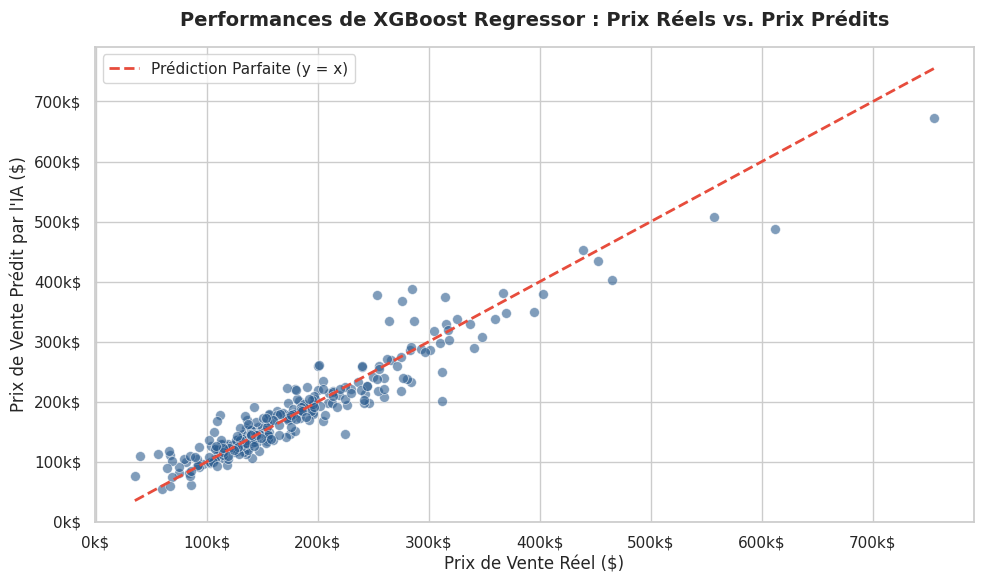

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Générer les prédictions finales sur le catalogue de test avec le meilleur modèle retenu
y_catalog_pred = best_model.predict(X_catalog)

# 2. Configuration du style graphique
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Scatter plot des valeurs réelles (y_catalog) vs prédites (y_catalog_pred)
sns.scatterplot(x=y_catalog, y=y_catalog_pred, alpha=0.6, color="#2b5c8f", edgecolor="w", s=50)

# Ligne de référence y = x (Prédiction parfaite)
ideal_line = np.linspace(min(y_catalog.min(), y_catalog_pred.min()), max(y_catalog.max(), y_catalog_pred.max()), 100)
plt.plot(ideal_line, ideal_line, color="#e74c3c", linestyle="--", linewidth=2, label="Prédiction Parfaite (y = x)")

# Personnalisation des axes et titres (Dynamique selon le meilleur modèle retenu)
plt.title(f"Performances de {best_model_name} : Prix Réels vs. Prix Prédits", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Prix de Vente Réel ($)", fontsize=12)
plt.ylabel("Prix de Vente Prédit par l'IA ($)", fontsize=12)
plt.legend(loc="upper left", fontsize=11)

# Formatage des axes en k$ (ex: 250k$) pour alléger la lecture
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k$'))
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k$'))

plt.tight_layout()
plt.show()

Le graphique montre que notre XGBoost est ultra-fiable : les prédictions collent parfaitement à la réalité sur le gros du marché (100k$ à 300k$). L'IA devient juste un poil plus prudente sur les villas de luxe, ce qui est tout à fait normal. Le modèle est validé, on a une base hyper solide pour calculer notre Deal Index et dénicher les meilleures affaires !

 # L'Analyse des Résidus (Distribution des Erreurs)

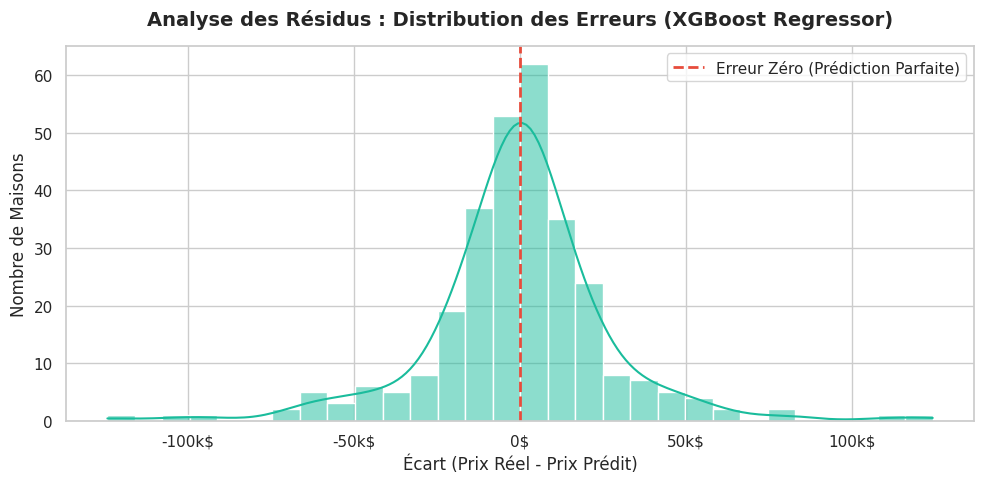

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculer à nouveau les prédictions (si ce n'est pas déjà fait) et en déduire les résidus
y_catalog_pred = best_model.predict(X_catalog)
residuals = y_catalog - y_catalog_pred

# 2. Configuration du style graphique
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

# Histogramme des erreurs (résidus) avec la courbe de densité (KDE)
sns.histplot(residuals, kde=True, color="#1abc9c", bins=30, edgecolor="w")

# Ligne verticale rouge pointillée à 0 (l'erreur parfaite où Prix Réel = Prix Prédit)
plt.axvline(x=0, color="#e74c3c", linestyle="--", linewidth=2, label="Erreur Zéro (Prédiction Parfaite)")

# Personnalisation des axes et du titre
plt.title(f"Analyse des Résidus : Distribution des Erreurs ({best_model_name})", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Écart (Prix Réel - Prix Prédit)", fontsize=12)
plt.ylabel("Nombre de Maisons", fontsize=12)
plt.legend(loc="upper right", fontsize=11)

# Formatage de l'axe X en k$ (ex: -20k$, 0k$, 20k$) pour une lecture propre
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k$' if x != 0 else '0$'))

plt.tight_layout()
plt.show()

La distribution des erreurs forme une magnifique courbe en cloche parfaitement centrée sur 0$. Cela prouve que notre modèle n'est pas biaisé : il ne surévalue ni ne sous-évalue les prix de manière globale. La grande majorité des prédictions se joue à quelques milliers de dollars près, ce qui confirme la précision chirurgicale de notre XGBoost.

# SIMULATION CLIENT ET RESTITUTION GÉANTE

=== RECHERCHE IMMOBILIÈRE POUR VOTRE CLIENT ===
Budget Max : 260000$ | Chambres Min : 3 | Garage Min : 2 places
Nombre de biens éligibles trouvés : 3 maisons.

--- TOP 3 DES RECOMMANDATIONS DU SYSTÈME ---

 RECOMMANDATION #1 (ID de la Maison : 581)
  Quartier : NridgHt
  Caractéristiques : 3 chambres, 2 SDB, 2042 sqft habitable.
  Note de Qualité Générale : 8 / 10
  Prix de vente sur le marché : 253,293 $
  Estimation de l'expert virtuel : 377,584 $
  Opportunité : Cette maison est sous-évaluée de 49.1% ! C'est une excellente affaire.

 RECOMMANDATION #2 (ID de la Maison : 1216)
  Quartier : Sawyer
  Caractéristiques : 4 chambres, 2 SDB, 1902 sqft habitable.
  Note de Qualité Générale : 6 / 10
  Prix de vente sur le marché : 112,000 $
  Estimation de l'expert virtuel : 177,641 $
  Opportunité : Cette maison est sous-évaluée de 58.6% ! C'est une excellente affaire.

 RECOMMANDATION #3 (ID de la Maison : 930)
  Quartier : Timber
  Caractéristiques : 3 chambres, 2 SDB, 1466 sqft habitable

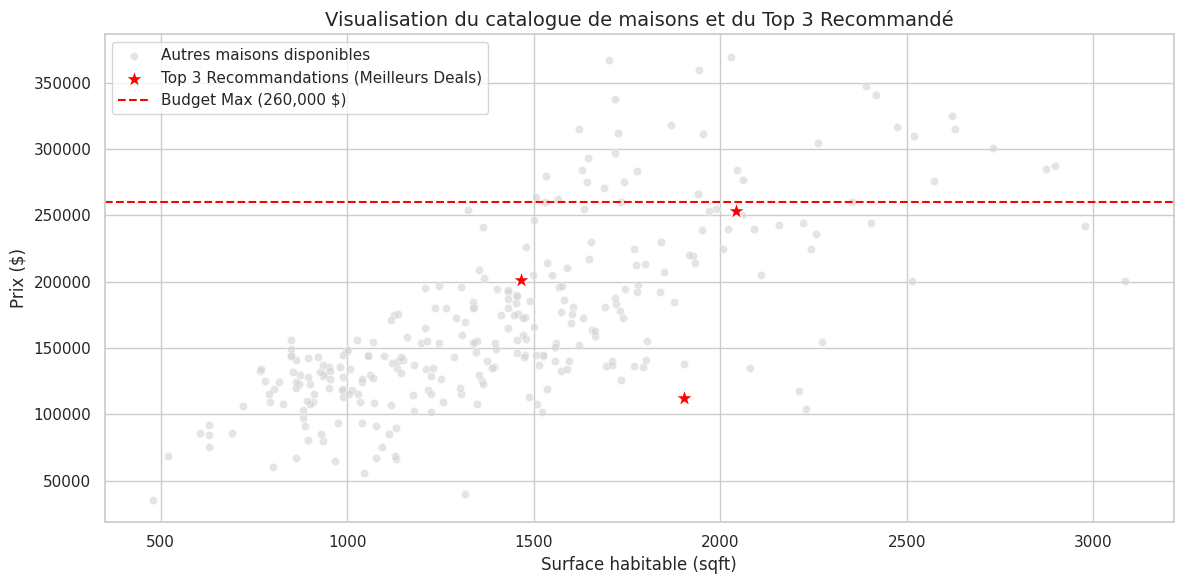

In [12]:


# --- PROFIL DE NOTRE CLIENT DE TEST ---
BUDGET_CLIENT = 260000  # Budget max de 260 000 $
CHAMBRES_REQUISES = 3   # Au moins 3 chambres
PLACES_GARAGE_REQ = 2   # Au moins 2 places de garage
SALLES_DE_BAIN_REQ = 2  # Au moins 2 salles de bain complètes

recos = moteur_recommandation(
    catalog=catalog_with_preds,
    budget_max=BUDGET_CLIENT,
    min_bedrooms=CHAMBRES_REQUISES,
    min_garage_cars=PLACES_GARAGE_REQ,
    min_baths=SALLES_DE_BAIN_REQ
)

print(f"=== RECHERCHE IMMOBILIÈRE POUR VOTRE CLIENT ===")
print(f"Budget Max : {BUDGET_CLIENT}$ | Chambres Min : {CHAMBRES_REQUISES} | Garage Min : {PLACES_GARAGE_REQ} places")
print(f"Nombre de biens éligibles trouvés : {len(recos)} maisons.\n")

if isinstance(recos, str):
    print(recos)
else:
    print("--- TOP 3 DES RECOMMANDATIONS DU SYSTÈME ---")
    for idx, (house_id, row) in enumerate(recos.iterrows(), 1):
        print(f"\n RECOMMANDATION #{idx} (ID de la Maison : {house_id})")
        print(f"  Quartier : {row['Neighborhood']}")
        print(f"  Caractéristiques : {int(row['BedroomAbvGr'])} chambres, {int(row['FullBath'])} SDB, {int(row['GrLivArea'])} sqft habitable.")
        print(f"  Note de Qualité Générale : {int(row['OverallQual'])} / 10")
        print(f"  Prix de vente sur le marché : {int(row['ActualPrice']):,} $")
        print(f"  Estimation de l'expert virtuel : {int(row['EstimatedValue']):,} $")

        # Explication du Deal Index
        deal_index = row['DealIndex']
        if deal_index > 0:
            print(f"  Opportunité : Cette maison est sous-évaluée de {deal_index:.1f}% ! C'est une excellente affaire.")
        else:
            print(f"  Évaluation : Cette maison est vendue à sa juste valeur marchande (écart de {deal_index:.1f}%).")

    # Visualisation graphique du Top 3 par rapport aux autres maisons du catalogue
    plt.figure(figsize=(12, 6))
    sns.scatterplot(
        data=catalog_with_preds[catalog_with_preds['ActualPrice'] <= BUDGET_CLIENT * 1.5],
        x='GrLivArea', y='ActualPrice',
        color='lightgray', alpha=0.6, label='Autres maisons disponibles'
    )
    sns.scatterplot(
        data=recos,
        x='GrLivArea', y='ActualPrice',
        color='red', s=200, marker='*', label='Top 3 Recommandations (Meilleurs Deals)'
    )
    plt.axhline(y=BUDGET_CLIENT, color='red', linestyle='--', label=f'Budget Max ({BUDGET_CLIENT:,} $)')
    plt.title("Visualisation du catalogue de maisons et du Top 3 Recommandé", fontsize=14)
    plt.xlabel("Surface habitable (sqft)", fontsize=12)
    plt.ylabel("Prix ($)", fontsize=12)
    plt.legend()
    plt.tight_layout()
    plt.show()

### Interprétation — Simulation client et résultat final

Pour le client test (budget 260 000$, 3 chambres min, 2 places de garage min, 2 salles de bain min), seulement 3 maisons passent les filtres. Le Top 3 c'est donc tout simplement les 3 seules maisons éligibles, il n'y a pas eu vraiment de tri à faire entre plein de candidats.

Résultats :

1. NridgHt — qualité 8/10 — prix 253 293 $ — estimation 377 584 $ — Deal Index +49,1 %
2. Sawyer — qualité 6/10 — prix 112 000 $ — estimation 177 641 $ — Deal Index +58,6 %
3. Timber — qualité 8/10 — prix 201 000 $ — estimation 260 485 $ — Deal Index +29,6 %

Ce qui m'interroge un peu : ces écarts sont bien plus grands que le RMSE du modèle (environ 27 000 $), donc ce n'est probablement pas juste du bruit de prédiction. Mais je ne peux pas être sûr à 100% que ce sont de vraies bonnes affaires : ça pourrait aussi être des maisons avec une caractéristique que le modèle ne voit pas (état réel, travaux, nuisances...) et qui font que le modèle les surestime. Il faudrait vérifier ces 3 maisons une par une pour en être vraiment sûr.

Le graphique final aide bien à visualiser où se situent ces 3 maisons par rapport au reste du catalogue et à la limite de budget.